In [1]:
# ============================================================================
# MBERT: Multilingual BERT for Multi-Task Complaint Classification
# Using MBERT Base Model - COMPLETE NOTEBOOK
# ============================================================================

# ----------------------------------------------------------------------------
# CELL 1: IMPORTS AND SYSTEM SETUP
# ----------------------------------------------------------------------------

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ----------------------------------------------------------------------------
# CELL 2: CONFIGURATION
# ----------------------------------------------------------------------------

class Config:
    """Configuration settings for MBERT"""
    
    # Base Model - Using Multilingual BERT
    BASE_MODEL = 'mbert'
    MBERT_PATH = "bert-base-multilingual-cased"
    
    # Directories
    PROJECT_DIR = os.getcwd()
    DATA_DIR = os.path.join(PROJECT_DIR, "Synthetic_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # Output - Separate directory for MBERT results
    BASE_DIR = os.path.join(PROJECT_DIR, "mbert_results")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # Training
    MAX_LENGTH = 128
    BATCH_SIZE = 32
    EPOCHS = 15
    LEARNING_RATE = 2e-5
    DROPOUT = 0.2
    WEIGHT_DECAY = 0.01
    WARMUP_RATIO = 0.1
    NUM_WORKERS = 0  # Set to 0 for Windows compatibility
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # Hugging Face Token
    HF_TOKEN = os.getenv("HF_TOKEN")


print("=" * 80)
print("MBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE}")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

MBERT CONFIGURATION

[BATCH SIZE] 32
[EPOCHS] 15
[LEARNING RATE] 2e-05
[DEVICE] cuda


In [3]:
# ----------------------------------------------------------------------------
# CELL 3: LOAD DATA
# ----------------------------------------------------------------------------

print("Loading datasets...")
train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df = pd.read_csv(Config.DEV_PATH)
test_df = pd.read_csv(Config.TEST_PATH)
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# Quick distribution
print("\nPrimary Category Distribution (Train):")
print(train_df['primary_category'].value_counts())

print("\nSeverity Distribution (Train):")
print(train_df['Severity'].value_counts())

Loading datasets...
Train: 10500, Dev: 2250, Test: 2250

Primary Category Distribution (Train):
primary_category
Waste Management                       1315
Road & Transportation                  1314
Electricity                            1314
Water Leakage                          1313
Health & Sanitation                    1311
Encroachment & Illegal Construction    1311
Public Safety                          1311
Others                                 1311
Name: count, dtype: int64

Severity Distribution (Train):
Severity
High      3522
Medium    3503
Low       3475
Name: count, dtype: int64


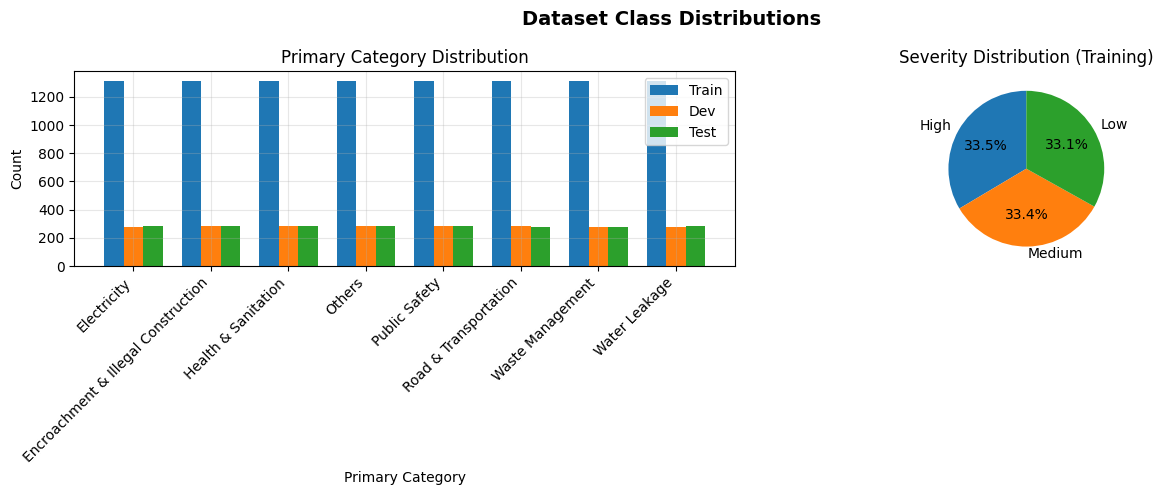

In [4]:
# ----------------------------------------------------------------------------
# CELL 4: VISUALIZE CLASS DISTRIBUTIONS
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Primary categories
train_counts = train_df['primary_category'].value_counts()
dev_counts = dev_df['primary_category'].value_counts()
test_counts = test_df['primary_category'].value_counts()

categories = sorted(train_counts.index.tolist())
x = np.arange(len(categories))
width = 0.25

axes[0].bar(x - width, [train_counts.get(c, 0) for c in categories], width, label='Train')
axes[0].bar(x, [dev_counts.get(c, 0) for c in categories], width, label='Dev')
axes[0].bar(x + width, [test_counts.get(c, 0) for c in categories], width, label='Test')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('Count')
axes[0].set_title('Primary Category Distribution')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Severity
severity_counts = train_df['Severity'].value_counts()
axes[1].pie(severity_counts.values, labels=severity_counts.index, 
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Severity Distribution (Training)')

plt.suptitle('Dataset Class Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/class_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# ----------------------------------------------------------------------------
# CELL 5: PREPROCESS DATA
# ----------------------------------------------------------------------------

class Preprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def preprocess_text(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("Preparing labels...")
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)})")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        print(f"Final: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

preprocessor = Preprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("✅ Data preprocessing completed")

Preprocessing text...
Preparing labels...
Primary: 8, Subcat: 24, Severity: 3)
Final: Train 10500, Dev 2250, Test 2250
✅ Data preprocessing completed


In [6]:
# ----------------------------------------------------------------------------
# CELL 6: PRE-TOKENIZED DATASET CLASS
# ----------------------------------------------------------------------------

class PreTokenizedDataset(Dataset):
    """Pre-tokenizes all data once to avoid re-tokenization during training"""
    def __init__(self, df, tokenizer, max_length=128):
        print("Pre-tokenizing dataset...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        # Pre-tokenize all texts
        texts = df["text"].astype(str).tolist()
        
        # Use batch tokenization for speed
        encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        
        print(f"✅ Pre-tokenized {len(df)} samples")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }

In [7]:
# ----------------------------------------------------------------------------
# CELL 7: MBERT MODEL FOR MULTI-TASK CLASSIFICATION
# ----------------------------------------------------------------------------

class MBERTMultiTask(nn.Module):
    """
    MBERT model for multi-task classification:
    - Primary category classification (8 classes)
    - Sub-category classification (24 classes)
    - Severity classification (3 classes)
    """
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        # Multi-task classification heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        """
        Forward pass through MBERT.
        
        Args:
            input_ids: Token IDs
            attention_mask: Attention mask
            sentiment: Optional sentiment scores (not used in base model)
        
        Returns:
            Tuple of (primary_logits, subcat_logits, severity_logits)
        """
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token embedding
        
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract [CLS] token embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [8]:
# ----------------------------------------------------------------------------
# CELL 8: LOAD BASE MODEL
# ----------------------------------------------------------------------------

print("Loading MBERT model...")

# Try loading with token, fallback to without if needed
try:
    tokenizer = AutoTokenizer.from_pretrained(
        Config.MBERT_PATH,
        token=Config.HF_TOKEN,
        use_fast=True
    )
    base_model = AutoModel.from_pretrained(
        Config.MBERT_PATH,
        token=Config.HF_TOKEN
    ).to(Config.DEVICE)
except Exception as e:
    print(f"⚠️ Token authentication failed: {e}")
    print("Loading without token...")
    tokenizer = AutoTokenizer.from_pretrained(
        Config.MBERT_PATH,
        use_fast=True
    )
    base_model = AutoModel.from_pretrained(
        Config.MBERT_PATH
    ).to(Config.DEVICE)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = MBERTMultiTask(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading MBERT model...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12552.32it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 119547, Hidden: 768
✅ Model loaded: 178,470,947 parameters


In [9]:
# ----------------------------------------------------------------------------
# CELL 9: CREATE DATALOADERS WITH PRE-TOKENIZATION
# ----------------------------------------------------------------------------

print("Creating pre-tokenized datasets...")
train_dataset = PreTokenizedDataset(train_df, tokenizer, Config.MAX_LENGTH)
dev_dataset = PreTokenizedDataset(dev_df, tokenizer, Config.MAX_LENGTH)
test_dataset = PreTokenizedDataset(test_df, tokenizer, Config.MAX_LENGTH)

# Create dataloaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=Config.BATCH_SIZE, 
    shuffle=True,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
dev_loader = DataLoader(
    dev_dataset, 
    batch_size=Config.BATCH_SIZE * 2, 
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset, 
    batch_size=Config.BATCH_SIZE * 2, 
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")

# Test one batch
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"✅ First batch loaded successfully!")
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels shapes: Primary={test_batch['primary'].shape}, "
      f"Subcat={test_batch['subcat'].shape}, "
      f"Severity={test_batch['severity'].shape}")
print("✅ Data loader working!")

Creating pre-tokenized datasets...
Pre-tokenizing dataset...
✅ Pre-tokenized 10500 samples
Pre-tokenizing dataset...
✅ Pre-tokenized 2250 samples
Pre-tokenizing dataset...
✅ Pre-tokenized 2250 samples
Train batches: 329, Dev: 36, Test: 36

Testing data loader...
✅ First batch loaded successfully!
Input shape: torch.Size([32, 128])
Labels shapes: Primary=torch.Size([32]), Subcat=torch.Size([32]), Severity=torch.Size([32])
✅ Data loader working!


In [10]:
# ----------------------------------------------------------------------------
# CELL 10: TRAINING FUNCTIONS
# ----------------------------------------------------------------------------

class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    """Early stops training if validation metric doesn't improve after a given patience."""
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler):
    """Optimized training with mixed precision"""
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        
        # Mixed precision forward pass
        with autocast():
            p1, p2, p3 = model(input_ids, attention_mask)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Mixed precision backward pass
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item()
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.3f}'})
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate(model, dataloader, device, return_predictions=False):
    """Evaluate model on given dataloader"""
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [11]:
# ----------------------------------------------------------------------------
# CELL 11: SETUP TRAINING
# ----------------------------------------------------------------------------

optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

early_stopping = EarlyStopping(patience=5, mode='max')
scaler = GradScaler()

print(f"Training setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed Precision: Enabled")

Training setup:
  Total batches per epoch: 329
  Total steps: 4935
  Warmup steps: 493
  Mixed Precision: Enabled


In [12]:
# ----------------------------------------------------------------------------
# CELL 12: TRAINING LOOP
# ----------------------------------------------------------------------------

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING MBERT")
print("="*80 + "\n")

# Test forward pass
print("Testing forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"Epoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training with mixed precision
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_mbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING MBERT

Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/15
--------------------------------------------------


Train Loss: 4.1467 | Acc: 0.4909 | Bal Acc: 0.4908
Val Acc: 0.8893 | Bal Acc: 0.8894 | F1: 0.8888
Task Losses: Primary=1.364, Subcat=2.298, Severity=0.970
Epoch Time: 2033.8s
✓ New best model saved! F1: 0.8888
Epoch 2/15
--------------------------------------------------


Train Loss: 1.1705 | Acc: 0.9139 | Bal Acc: 0.9139
Val Acc: 0.9293 | Bal Acc: 0.9293 | F1: 0.9292
Task Losses: Primary=0.281, Subcat=0.617, Severity=0.545
Epoch Time: 2037.4s
✓ New best model saved! F1: 0.9292
Epoch 3/15
--------------------------------------------------


Train Loss: 0.6686 | Acc: 0.9482 | Bal Acc: 0.9482
Val Acc: 0.9373 | Bal Acc: 0.9373 | F1: 0.9369
Task Losses: Primary=0.163, Subcat=0.349, Severity=0.314
Epoch Time: 2038.2s
✓ New best model saved! F1: 0.9369
Epoch 4/15
--------------------------------------------------


Train Loss: 0.4170 | Acc: 0.9709 | Bal Acc: 0.9709
Val Acc: 0.9582 | Bal Acc: 0.9582 | F1: 0.9582
Task Losses: Primary=0.093, Subcat=0.220, Severity=0.209
Epoch Time: 2037.2s
✓ New best model saved! F1: 0.9582
Epoch 5/15
--------------------------------------------------


Train Loss: 0.2888 | Acc: 0.9808 | Bal Acc: 0.9808
Val Acc: 0.9587 | Bal Acc: 0.9586 | F1: 0.9586
Task Losses: Primary=0.063, Subcat=0.157, Severity=0.137
Epoch Time: 2039.0s
✓ New best model saved! F1: 0.9586
Epoch 6/15
--------------------------------------------------


... (6 outputs left out)

Train Loss: 0.0285 | Acc: 0.9994 | Bal Acc: 0.9994
Val Acc: 0.9662 | Bal Acc: 0.9662 | F1: 0.9661
Task Losses: Primary=0.002, Subcat=0.023, Severity=0.005
Epoch Time: 2037.1s
✓ New best model saved! F1: 0.9661
Epoch 13/15
--------------------------------------------------


Train Loss: 0.0238 | Acc: 0.9995 | Bal Acc: 0.9995
Val Acc: 0.9644 | Bal Acc: 0.9644 | F1: 0.9644
Task Losses: Primary=0.002, Subcat=0.020, Severity=0.003
Epoch Time: 2039.4s
Epoch 14/15
--------------------------------------------------


Train Loss: 0.0212 | Acc: 0.9996 | Bal Acc: 0.9996
Val Acc: 0.9662 | Bal Acc: 0.9662 | F1: 0.9661
Task Losses: Primary=0.002, Subcat=0.018, Severity=0.003
Epoch Time: 2037.8s
Epoch 15/15
--------------------------------------------------


Train Loss: 0.0189 | Acc: 0.9998 | Bal Acc: 0.9998
Val Acc: 0.9662 | Bal Acc: 0.9662 | F1: 0.9661
Task Losses: Primary=0.001, Subcat=0.017, Severity=0.002
Epoch Time: 2038.0s
Early stopping triggered after 15 epochs

✅ Training completed in 509.9 minutes


In [13]:
# ----------------------------------------------------------------------------
# CELL 13: FINAL TEST EVALUATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Load best model
checkpoint_path = f"{Config.MODEL_DIR}/best_mbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL,
    'total_training_time': total_time
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9640
  balanced_accuracy: 0.9639
  f1_macro: 0.9640
  f1_weighted: 0.9640
  precision: 0.9644
  recall: 0.9640
  cohen_kappa: 0.9589
  mcc: 0.9589

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\results


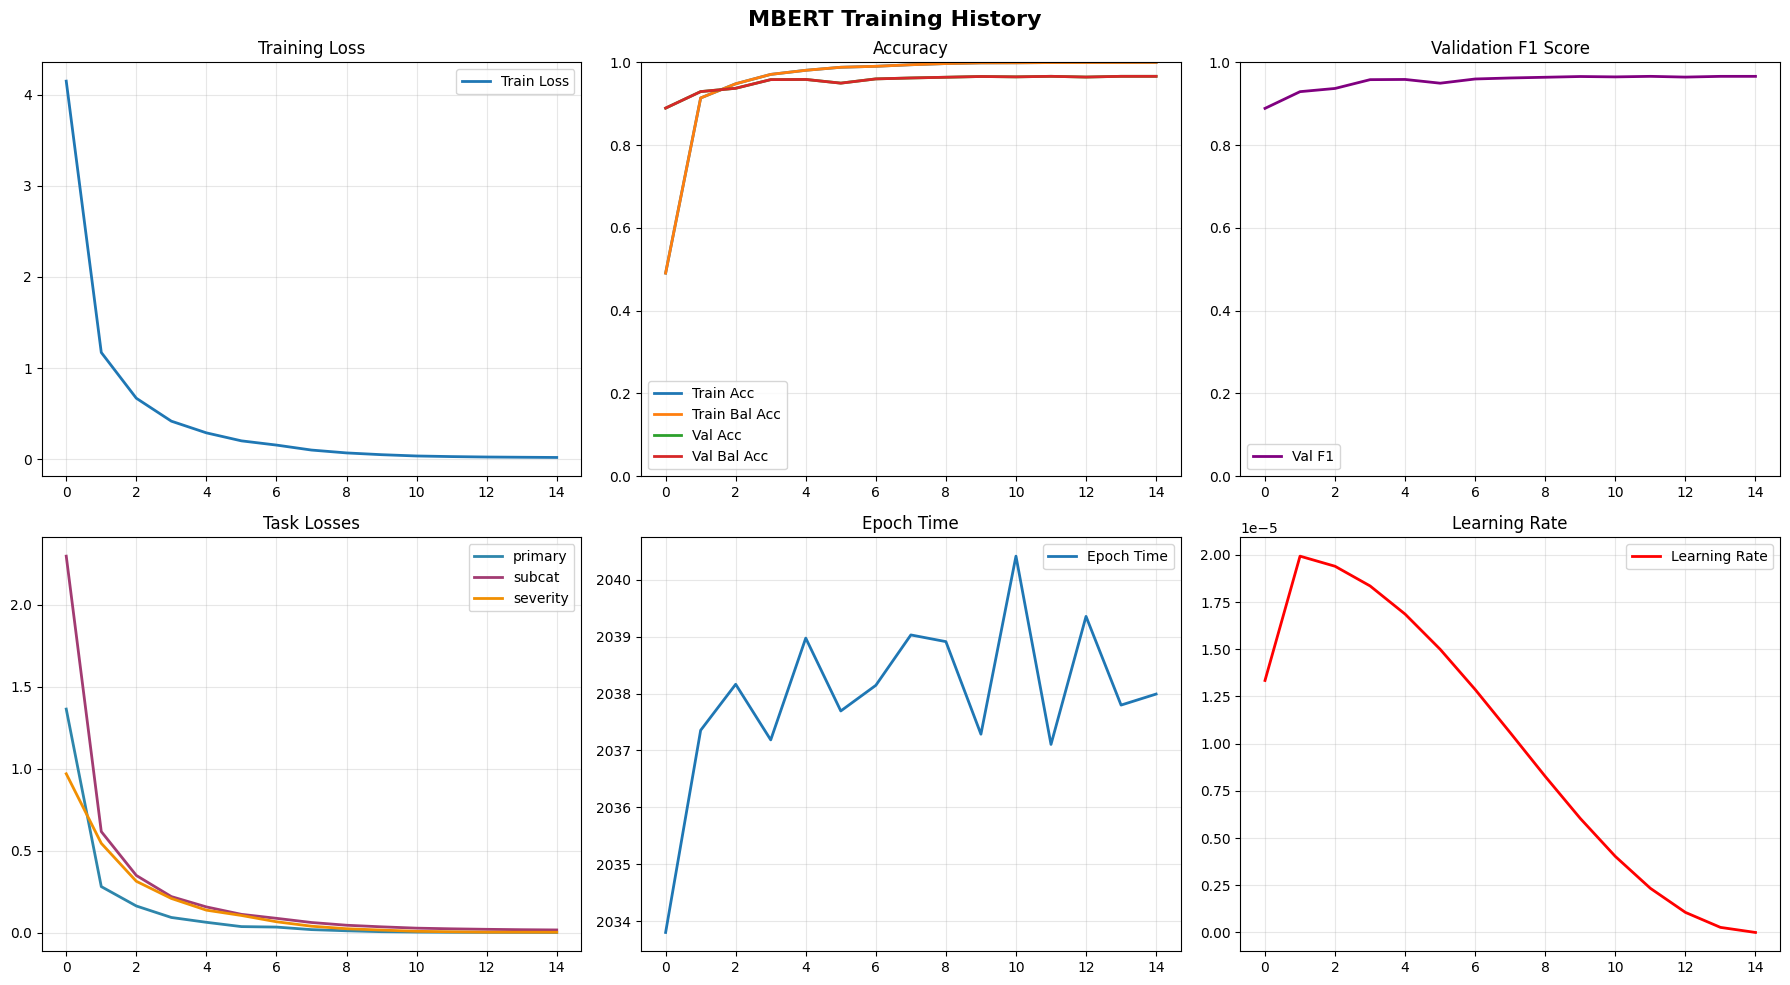

In [14]:
# ----------------------------------------------------------------------------
# CELL 14: TRAINING HISTORY VISUALIZATION
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Training loss
axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
axes[0, 0].set_title('Training Loss')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Accuracy
axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# F1 Score
axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
axes[0, 2].set_title('Validation F1 Score')
axes[0, 2].set_ylim(0, 1)
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

# Task losses
task_names = ['primary', 'subcat', 'severity']
colors = ['#2E86AB', '#A23B72', '#F18F01']
for task, color in zip(task_names, colors):
    values = [h['task_losses'][task] for h in train_history]
    axes[1, 0].plot(values, label=task, linewidth=2, color=color)
axes[1, 0].set_title('Task Losses')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# Epoch time
axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
axes[1, 1].set_title('Epoch Time')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

# Learning rate
axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
axes[1, 2].set_title('Learning Rate')
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

plt.suptitle(f'MBERT Training History', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/training_history.png", dpi=300, bbox_inches='tight')
plt.show()

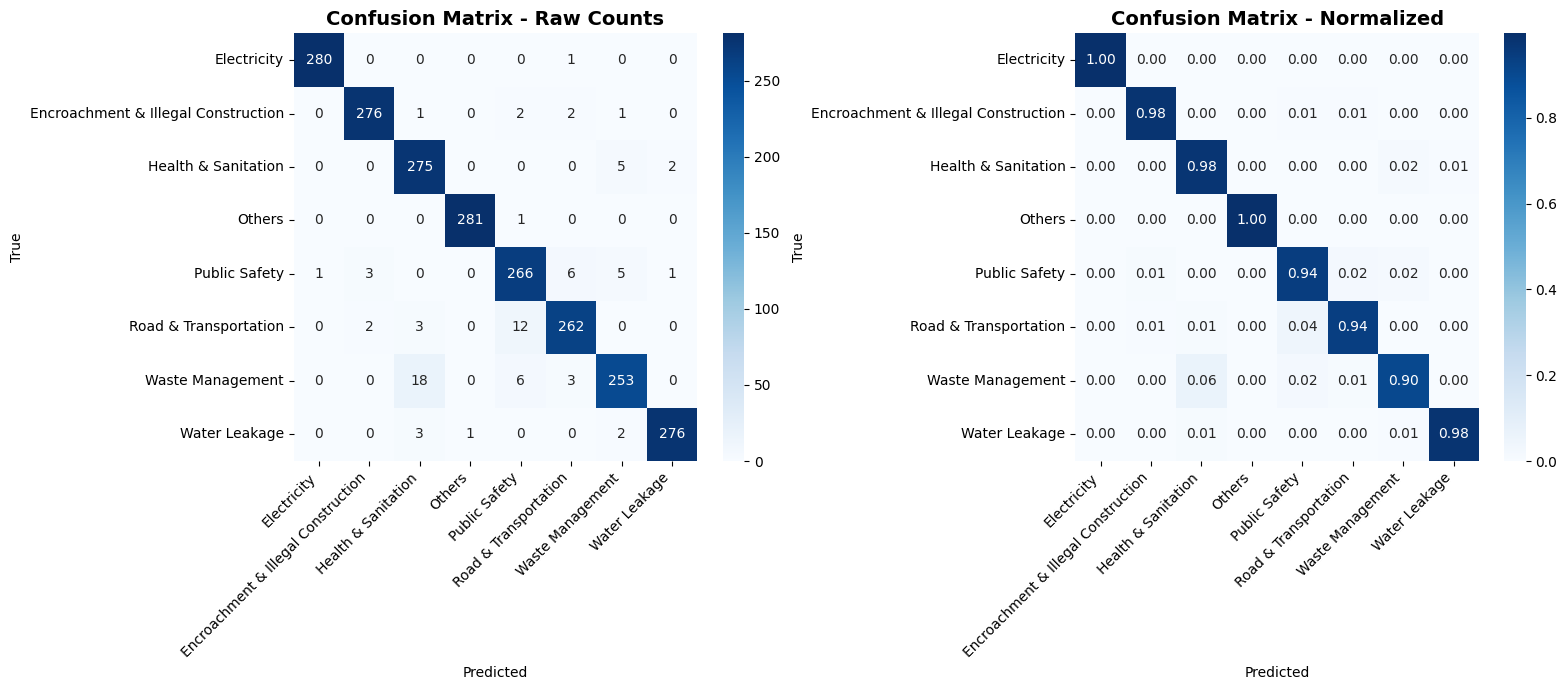

✅ Confusion matrix saved


In [15]:
# ----------------------------------------------------------------------------
# CELL 15: CONFUSION MATRIX
# ----------------------------------------------------------------------------

cm = confusion_matrix(test_labels, test_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
class_names = preprocessor.le_primary.classes_

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - Raw Counts', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix - Normalized', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved")


T-SNE EMBEDDING VISUALIZATION


Extracting embeddings: 100%|██████████| 36/36 [02:41<00:00,  4.49s/it]


Reducing dimensions with PCA...
Running t-SNE...


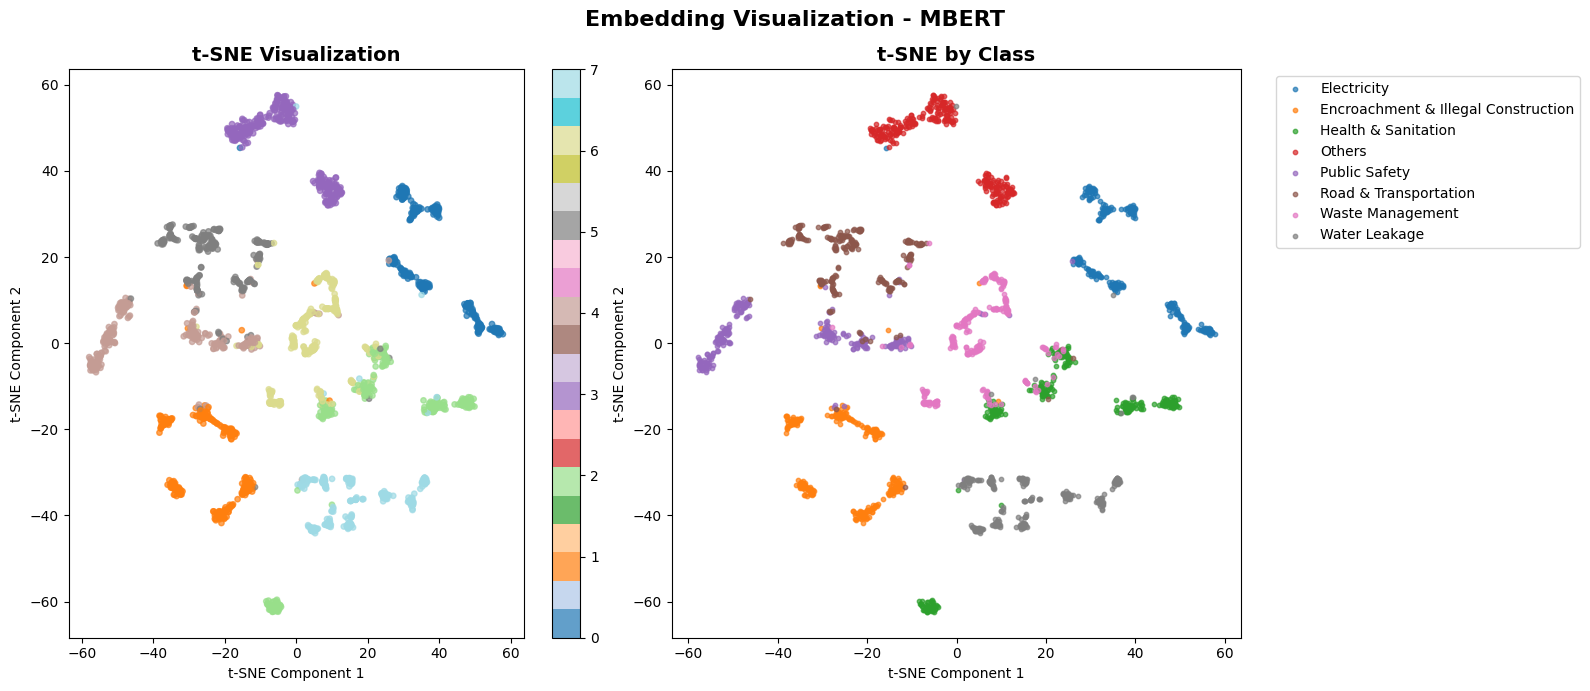

✅ t-SNE visualization saved


In [16]:
# ----------------------------------------------------------------------------
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("T-SNE EMBEDDING VISUALIZATION")
print("="*80)

model.eval()
embeddings, labels = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Extracting embeddings"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        emb = model.get_embeddings(input_ids, attention_mask)
        embeddings.append(emb.cpu().numpy())
        labels.extend(batch['primary'].cpu().numpy())

embeddings = np.vstack(embeddings)
labels = np.array(labels)

# PCA then t-SNE
print("Reducing dimensions with PCA...")
pca = PCA(n_components=50)
embeddings_pca = pca.fit_transform(embeddings)

print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
embeddings_tsne = tsne.fit_transform(embeddings_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# t-SNE scatter
scatter = axes[0].scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1], 
                          c=labels, cmap='tab20', s=15, alpha=0.7)
axes[0].set_title('t-SNE Visualization', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Component 1')
axes[0].set_ylabel('t-SNE Component 2')
plt.colorbar(scatter, ax=axes[0])

# By class
for i, class_name in enumerate(class_names):
    mask = labels == i
    if np.sum(mask) > 0:
        axes[1].scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                       label=class_name, s=10, alpha=0.7)
axes[1].set_title('t-SNE by Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.suptitle(f'Embedding Visualization - MBERT', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ t-SNE visualization saved")

In [17]:
# ----------------------------------------------------------------------------
# CELL 17: CLASSIFICATION REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(test_labels, test_preds, target_names=class_names, digits=4)
print(report)

with open(f"{Config.RESULTS_DIR}/classification_report.txt", 'w') as f:
    f.write("Classification Report\n")
    f.write("="*60 + "\n")
    f.write(report)


CLASSIFICATION REPORT
                                     precision    recall  f1-score   support

                        Electricity     0.9964    0.9964    0.9964       281
Encroachment & Illegal Construction     0.9822    0.9787    0.9805       282
                Health & Sanitation     0.9167    0.9752    0.9450       282
                             Others     0.9965    0.9965    0.9965       282
                      Public Safety     0.9268    0.9433    0.9350       282
              Road & Transportation     0.9562    0.9391    0.9476       279
                   Waste Management     0.9511    0.9036    0.9267       280
                      Water Leakage     0.9892    0.9787    0.9840       282

                           accuracy                         0.9640      2250
                          macro avg     0.9644    0.9639    0.9640      2250
                       weighted avg     0.9644    0.9640    0.9640      2250



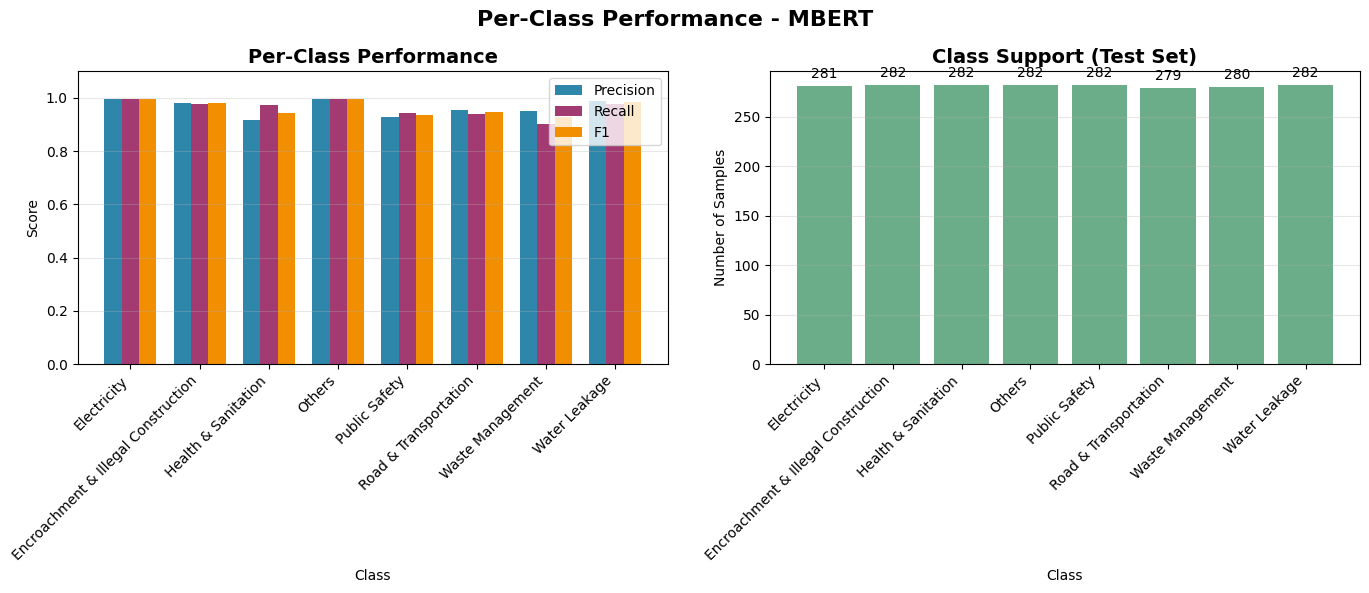

In [18]:
# ----------------------------------------------------------------------------
# CELL 18: PER-CLASS PERFORMANCE
# ----------------------------------------------------------------------------

from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    test_labels, test_preds, average=None, zero_division=0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

x = np.arange(len(class_names))
width = 0.25

axes[0].bar(x - width, precision, width, label='Precision', color='#2E86AB')
axes[0].bar(x, recall, width, label='Recall', color='#A23B72')
axes[0].bar(x + width, f1, width, label='F1', color='#F18F01')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Score')
axes[0].set_title('Per-Class Performance', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].set_ylim(0, 1.1)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(x, support, color='#2E8B57', alpha=0.7)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Samples')
axes[1].set_title('Class Support (Test Set)', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')

for i, s in enumerate(support):
    axes[1].text(i, s + 5, str(s), ha='center', va='bottom')

plt.suptitle(f'Per-Class Performance - MBERT', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/per_class_performance.png", dpi=300, bbox_inches='tight')
plt.show()

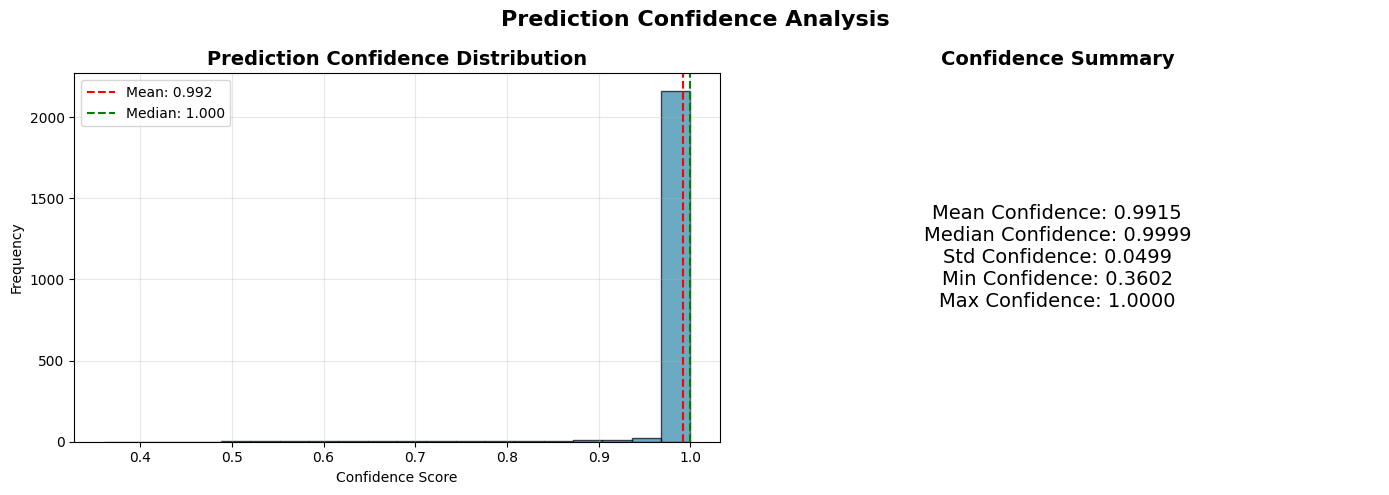

In [19]:
# ----------------------------------------------------------------------------
# CELL 19: CONFIDENCE ANALYSIS
# ----------------------------------------------------------------------------

confidences = test_metrics['confidences']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(confidences, bins=20, edgecolor='black', alpha=0.7, color='#2E86AB')
axes[0].set_xlabel('Confidence Score')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
axes[0].axvline(np.mean(confidences), color='red', linestyle='--', 
               label=f'Mean: {np.mean(confidences):.3f}')
axes[0].axvline(np.median(confidences), color='green', linestyle='--', 
               label=f'Median: {np.median(confidences):.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].text(0.5, 0.5, 
            f"Mean Confidence: {np.mean(confidences):.4f}\n"
            f"Median Confidence: {np.median(confidences):.4f}\n"
            f"Std Confidence: {np.std(confidences):.4f}\n"
            f"Min Confidence: {np.min(confidences):.4f}\n"
            f"Max Confidence: {np.max(confidences):.4f}",
            ha='center', va='center', fontsize=14,
            transform=axes[1].transAxes)
axes[1].set_title('Confidence Summary', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Prediction Confidence Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confidence_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
# ----------------------------------------------------------------------------
# CELL 20: SAVE MODEL AND ENCODERS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("SAVING MODEL AND ENCODERS")
print("="*80)

torch.save({
    'model_state_dict': model.state_dict(),
    'n_primary': model.n_primary,
    'n_subcat': model.n_subcat,
    'n_severity': model.n_severity,
    'hidden_size': model.hidden_size,
    'base_model': Config.BASE_MODEL
}, f"{Config.MODEL_DIR}/mbert_model.pt")

with open(f"{Config.MODEL_DIR}/le_primary.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_primary, f)
with open(f"{Config.MODEL_DIR}/le_subcat.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_subcat, f)
with open(f"{Config.MODEL_DIR}/le_severity.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_severity, f)

print(f"✅ Model saved to: {Config.MODEL_DIR}/mbert_model.pt")
print(f"✅ Label encoders saved to: {Config.MODEL_DIR}/le_*.pkl")


SAVING MODEL AND ENCODERS
✅ Model saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\models/mbert_model.pt
✅ Label encoders saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\models/le_*.pkl


In [21]:
# ----------------------------------------------------------------------------
# CELL 21: COMPLETE SUMMARY
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print(f"MBERT COMPLETE SUMMARY")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results: {Config.RESULTS_DIR}")
print(f"📁 Visualizations: {Config.VISUALIZATION_DIR}")
print(f"📁 Models: {Config.MODEL_DIR}")


MBERT COMPLETE SUMMARY

1. DATASET STATISTICS:
   Training: 10500, Validation: 2250, Test: 2250
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 178,470,947
   Hidden Size: 768
   Dropout: 0.2

3. TEST PERFORMANCE:
   accuracy: 0.9640
   balanced_accuracy: 0.9639
   f1_macro: 0.9640
   f1_weighted: 0.9640
   precision: 0.9644
   recall: 0.9640
   cohen_kappa: 0.9589
   mcc: 0.9589

4. BEST VALIDATION:
   F1: 0.9661, Balanced Accuracy: 0.9662

5. TRAINING TIME:
   Total: 509.9 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!

✅ All results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results
📁 Results: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\results
📁 Visualizations: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\visualizations
📁 Models: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\mbert_results\models
